# 01 — Exploratory Analysis

Load a single recording, inspect its contents, and check that the pipeline runs end-to-end.

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath('..'))   # make src/ importable

import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

from src.config import load_config
from src.data_io import load_h5, list_h5_files

cfg = load_config()
print('Conditions:', cfg['conditions'])
print('Processed dir:', cfg['paths']['processed_dir'])


Conditions: ['baseline', 'stimulation', 'post_stimulation']
Processed dir: c:\Users\leosp\OneDrive\Bureau\MSRL\fancy_modular_BCN_code\data/processed


## List available recordings

In [3]:
h5_files = list_h5_files(cfg['paths']['condition_dir'])
for f in h5_files:
    print(os.path.basename(f))


20260414_SLICE3_CONTROL_Nathalia_vitaly_trial_01_baseline.h5
20260414_SLICE3_CONTROL_Nathalia_vitaly_trial_01_post_stimulation.h5
20260414_SLICE3_CONTROL_Nathalia_vitaly_trial_01_stimulation.h5
20260414_SLICE3_CONTROL_Nathalia_vitaly_trial_02_baseline.h5
20260414_SLICE3_CONTROL_Nathalia_vitaly_trial_02_post_stimulation.h5
20260414_SLICE3_CONTROL_Nathalia_vitaly_trial_02_stimulation.h5
20260414_SLICE3_CONTROL_Nathalia_vitaly_trial_03_baseline.h5
20260414_SLICE3_CONTROL_Nathalia_vitaly_trial_03_post_stimulation.h5
20260414_SLICE3_CONTROL_Nathalia_vitaly_trial_03_stimulation.h5


## Load one recording and inspect metadata

In [9]:
H5_FILENAME = '20260414_SLICE3_CONTROL_Nathalia_vitaly_trial_01_post_stimulation.h5'


H5_PATH   = rf"C:\Users\leosp\OneDrive\Bureau\MSRL\fancy_modular_BCN_code\data\condition\{H5_FILENAME}"
CONDITION = 'baseline'   # must match config.yaml conditions list

data, meta = load_h5(H5_PATH)
print(f"Shape      : {data.shape}  (samples × channels)")
print(f"Sampling fs: {meta['fs']} Hz")
print(f"Duration   : {meta['duration_seconds']:.1f} s")
print(f"Units      : {meta['units']}")


Shape      : (140625, 32)  (samples × channels)
Sampling fs: 3125.0000000000005 Hz
Duration   : 45.0 s
Units      : uV


## Plot raw LFP

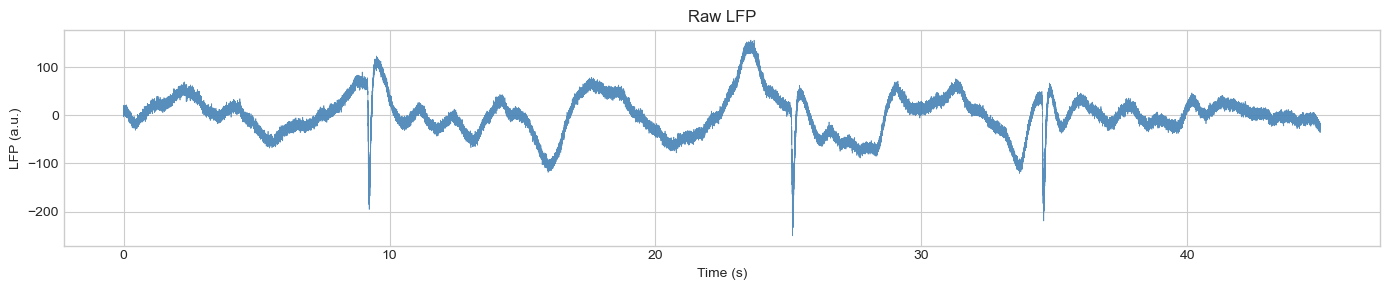

In [10]:
from src.visualization import plot_raw_lfp
from src.preprocessing import select_channel

lfp = select_channel(data, cfg['preprocessing'])

fig, ax = plot_raw_lfp(lfp, meta['fs'], cfg)
plt.tight_layout()
plt.show()



## Inspect feature signals

Feature matrix shape: (44800, 3)
Downsampled fs: 1000.0 Hz


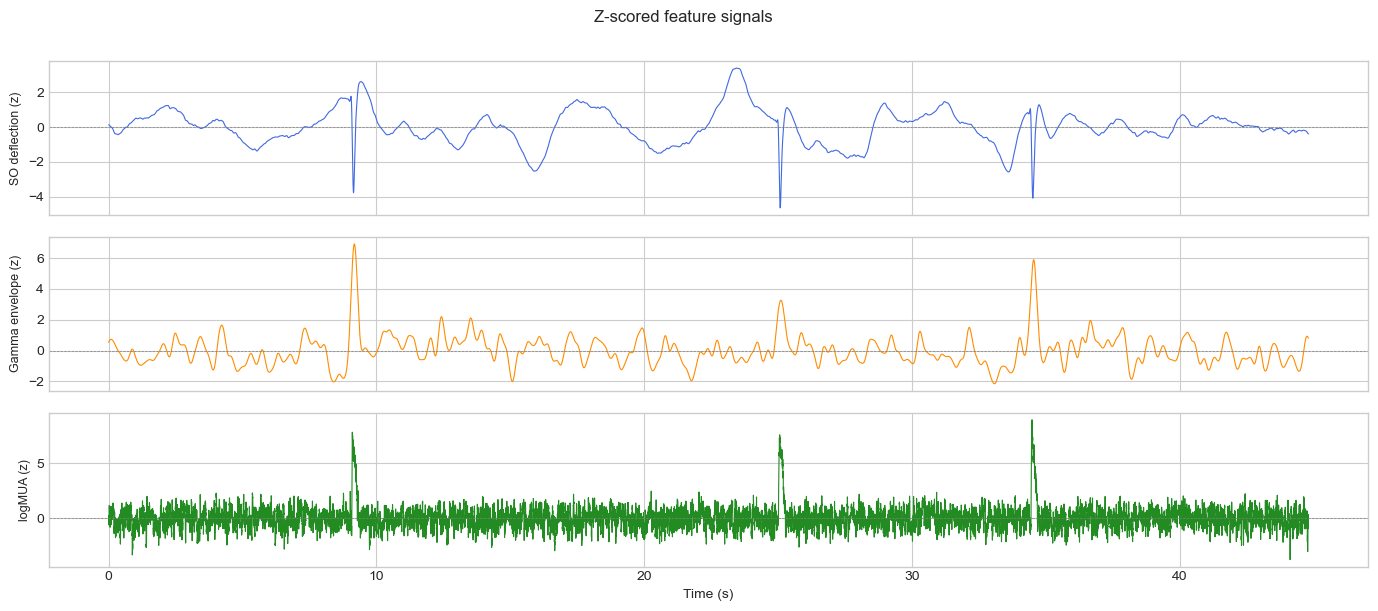

In [14]:
from src.preprocessing import extract_features
from src.visualization import plot_features

features, t_ds = extract_features(lfp, meta['fs'], cfg['preprocessing'])
print(f'Feature matrix shape: {features.shape}')
print(f'Downsampled fs: {1/(t_ds[1]-t_ds[0]):.1f} Hz')

fig, axes = plot_features(features, t_ds, cfg)
plt.show()


## Check PC1 distribution (should be bimodal)

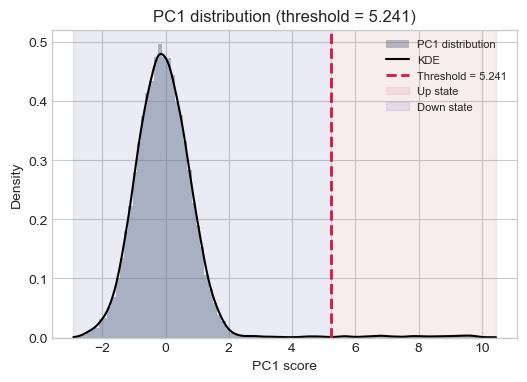

Up states detected  : 3
Down states detected: 4


In [12]:
from src.core.up_down import detect_states
from src.visualization import plot_pc1_distribution

states, epochs, pc1, threshold = detect_states(features, t_ds, cfg)

fig, ax = plot_pc1_distribution(pc1, threshold, cfg)
plt.title(f'PC1 distribution (threshold = {threshold:.3f})')
plt.show()

print(f'Up states detected  : {len(epochs["up"])}')
print(f'Down states detected: {len(epochs["down"])}')


## Overlay detected states on PC1 trace

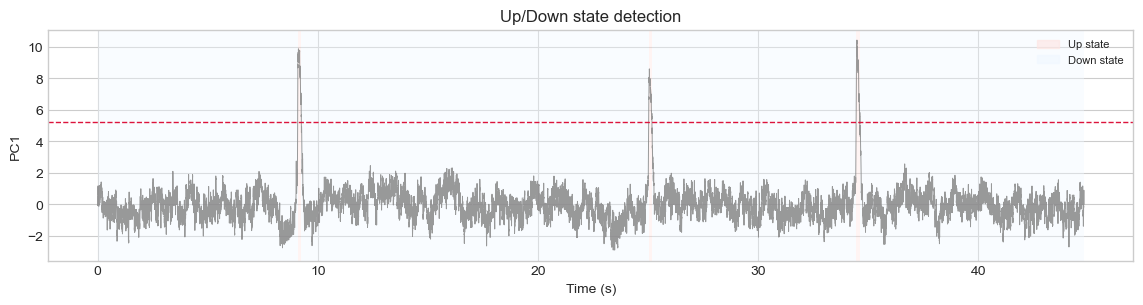

In [13]:
from src.visualization import plot_states_overlay

fig, ax = plot_states_overlay(t_ds, pc1, states, threshold, cfg, t_range_s=(0, 60))
plt.show()
